In [1]:
import configparser
import json
import os

import joblib
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

In [2]:
os.chdir('../')

In [3]:
data = configparser.ConfigParser(interpolation=configparser.ExtendedInterpolation())
data.read('data.ini')
data = data['DEFAULT']

In [4]:
with open(data['ml'] + 'tools_features_selection.json', 'r') as file:
    features_selections = json.load(file)

features_selections_genes = {}
for key, value in features_selections.items():
    features_selections_genes[key] = value['genes']

## muffinn maxHN - onlyRAS - onlyMutclust

In [5]:
suffix = 'merged_mut_["onlyMutclust - ALL"]'
modelsDir = f'{data['ml___models']}optimized_accuracy/{suffix}'
inputDir = f'{data['ml___input']}{suffix}'
key = 'muffinn maxHN - onlyRAS'

model_LRl_muffinnMaxHN_onlyRAS_onlyMutclust = joblib.load(f'{modelsDir}/[\"{key}\"]/logisticRegressionLasso.joblib')

scaler = joblib.load(f'{modelsDir}/[\"{key}\"]/scaler.joblib')

with open(f'{modelsDir}/[\"{key}\"]/features_info.json') as f:
    info_maxmifHN_onlyRAS_onlyMutclust = json.load(f)

train_RAS = pd.read_csv(f'{inputDir}/train_RAS.csv', index_col=0, sep='\t', comment='#', engine='python')
train_nonRAS = pd.read_csv(f'{inputDir}/train_nonRAS.csv', index_col=0, sep='\t', comment='#', engine='python')
test_RAS = pd.read_csv(f'{inputDir}/test_RAS.csv', index_col=0, sep='\t', comment='#', engine='python')
test_nonRAS = pd.read_csv(f'{inputDir}/test_nonRAS.csv', index_col=0, sep='\t', comment='#', engine='python')

train_muffinnMaxHN_onlyRAS_onlyMutclust = scaler.transform(pd.concat([train_RAS, train_nonRAS])[info_maxmifHN_onlyRAS_onlyMutclust['valid_features_train']])
test_muffinnMaxHN_onlyRAS_onlyMutclust = scaler.transform(pd.concat([test_RAS, test_nonRAS])[info_maxmifHN_onlyRAS_onlyMutclust['valid_features_train']])

In [6]:
weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust = pd.DataFrame({'feature': info_maxmifHN_onlyRAS_onlyMutclust['valid_features_train'], 'weight': model_LRl_muffinnMaxHN_onlyRAS_onlyMutclust.coef_[0]}).sort_values('weight', ascending=False)
weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust['gene'] = weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust['feature'].str.split('_').str[0]
weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust = weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust[['feature', 'gene', 'weight']]
weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust

,feature,gene,weight
15,PCBP1_100_102,PCBP1,0.491074
0,ANTXR1_438_439,ANTXR1,0.000000
14,PANX2_271_277,PANX2,0.000000
25,ZNF429_645_647,ZNF429,0.000000
24,UBQLN2_523_523,UBQLN2,0.000000
23,TIMP2_207_208,TIMP2,0.000000
22,TGIF1_201_213,TGIF1,0.000000
21,TAGAP_709_716,TAGAP,0.000000
20,RBM10_119_119,RBM10,0.000000
19,RASA2_654_654,RASA2,0.000000


In [7]:
plot_LRl_muffinnMaxHN_onlyRAS_onlyMutclust = pd.DataFrame(
    [(i, len(weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust.loc[weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust['weight'] > i, 'feature'])) for i in np.arange(weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust['weight'].max(), weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

Text(0.5, 1.0, 'maxmif HN - onlyRAS_onlyNonRAS - linearRegression : weight >')

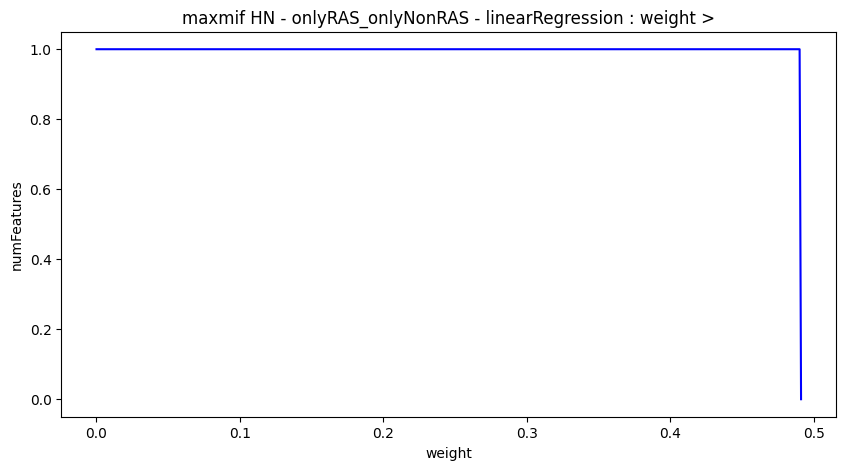

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

ax.plot(plot_LRl_muffinnMaxHN_onlyRAS_onlyMutclust['weight'], plot_LRl_muffinnMaxHN_onlyRAS_onlyMutclust['numFeatures'], color='blue')
ax.set_xlabel('weight')
ax.set_ylabel('numFeatures')
ax.set_title('maxmif HN - onlyRAS_onlyNonRAS - linearRegression : weight >')

In [9]:
RAS_significantFeatures_LRl_muffinnMaxHN_onlyRAS_onlyMutclust = set(weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust[weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust['weight'] > 0]['feature'])
weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust[weights_LRl_muffinnMaxHN_onlyRAS_onlyMutclust['feature'].isin(RAS_significantFeatures_LRl_muffinnMaxHN_onlyRAS_onlyMutclust)]

,feature,gene,weight
15,PCBP1_100_102,PCBP1,0.491074


In [10]:
len(train_RAS[train_RAS['PCBP1_100_102'] != 0]), len(train_nonRAS[train_nonRAS['PCBP1_100_102'] != 0]), len(test_RAS[test_RAS['PCBP1_100_102'] != 0]), len(test_nonRAS[test_nonRAS['PCBP1_100_102'] != 0])

(21, 3, 11, 5)

In [11]:
len(train_RAS), len(train_nonRAS), len(test_RAS), len(test_nonRAS)

(332, 451, 143, 193)

In [12]:
valid_features = info_maxmifHN_onlyRAS_onlyMutclust['valid_features_train']

In [13]:
len(train_RAS[valid_features].loc[~(train_RAS[valid_features] == 0).all(axis=1)]), \
len(train_nonRAS[valid_features].loc[~(train_nonRAS[valid_features] == 0).all(axis=1)]), \
len(test_RAS[valid_features].loc[~(test_RAS[valid_features] == 0).all(axis=1)]), \
len(test_nonRAS[valid_features].loc[~(test_nonRAS[valid_features] == 0).all(axis=1)])

(51, 54, 24, 33)

PCBP1:
- RNA binding protein that mediates transcription, translation and alternative splicing of mRNA molecules in a variety of contexts
- altered by mutation in Burkitt's lymphoma and gastrointestinal adenocarcinomas
    - these alterations are predicted to disrupt mRNA stability and alternative splicing
- regulates a diverse range of substrates implicated in oncogenesis and therefore can function as either a tumor suppressor or oncogene

## driverml	- RAS - onlyMutclust

In [14]:
suffix = 'merged_mut_["onlyMutclust - ALL"]'
modelsDir = f'{data['ml___models']}optimized_accuracy/{suffix}'
inputDir = f'{data['ml___input']}{suffix}'
key = 'driverml - RAS'

model_LRl_driverml_RAS_onlyMutclust = joblib.load(f'{modelsDir}/[\"{key}\"]/logisticRegressionLasso.joblib')

scaler = joblib.load(f'{modelsDir}/[\"{key}\"]/scaler.joblib')

with open(f'{modelsDir}/[\"{key}\"]/features_info.json') as f:
    info_driverml_RAS_onlyMutclust = json.load(f)

train_RAS = pd.read_csv(f'{inputDir}/train_RAS.csv', index_col=0, sep='\t', comment='#', engine='python')
train_nonRAS = pd.read_csv(f'{inputDir}/train_nonRAS.csv', index_col=0, sep='\t', comment='#', engine='python')
test_RAS = pd.read_csv(f'{inputDir}/test_RAS.csv', index_col=0, sep='\t', comment='#', engine='python')
test_nonRAS = pd.read_csv(f'{inputDir}/test_nonRAS.csv', index_col=0, sep='\t', comment='#', engine='python')

train_driverml_RAS_onlyMutclust = scaler.transform(pd.concat([train_RAS, train_nonRAS])[info_driverml_RAS_onlyMutclust['valid_features_train']])
test_driverml_RAS_onlyMutclust = scaler.transform(pd.concat([test_RAS, test_nonRAS])[info_driverml_RAS_onlyMutclust['valid_features_train']])

In [15]:
weights_LRl_driverml_RAS_onlyMutclust = pd.DataFrame({'feature': info_driverml_RAS_onlyMutclust['valid_features_train'], 'weight': model_LRl_driverml_RAS_onlyMutclust.coef_[0]}).sort_values('weight', ascending=False)
weights_LRl_driverml_RAS_onlyMutclust['gene'] = weights_LRl_driverml_RAS_onlyMutclust['feature'].str.split('_').str[0]
weights_LRl_driverml_RAS_onlyMutclust = weights_LRl_driverml_RAS_onlyMutclust[['feature', 'gene', 'weight']]
weights_LRl_driverml_RAS_onlyMutclust

,feature,gene,weight
313,PCBP1_100_102,PCBP1,0.174494
337,PIK3CA_545_546,PIK3CA,0.132447
24,APC_1281_1554,APC,0.123883
31,APC_874_876,APC,0.036314
445,TICAM1_642_642,TICAM1,0.021700
...,...,...,...
164,GJB5_124_129,GJB5,0.000000
502,ZNF98_102_123,ZNF98,0.000000
294,NRXN1_148_166,NRXN1,-0.005818
29,APC_564_564,APC,-0.026878


In [16]:
plot_LRl_driverml_RAS_onlyMutclust = pd.DataFrame(
    [(i, len(weights_LRl_driverml_RAS_onlyMutclust.loc[weights_LRl_driverml_RAS_onlyMutclust['weight'] > i, 'feature'])) for i in np.arange(weights_LRl_driverml_RAS_onlyMutclust['weight'].max(), weights_LRl_driverml_RAS_onlyMutclust['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

Text(0.5, 1.0, 'maxmif HN - onlyRAS_onlyNonRAS - linearRegression : weight >')

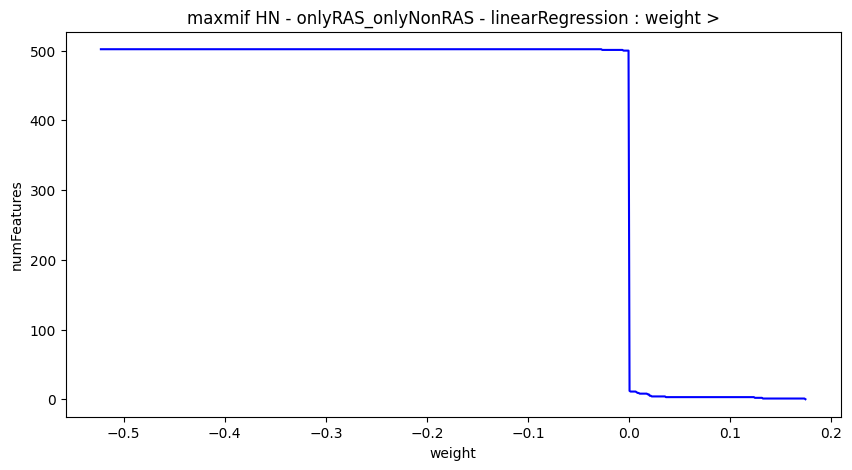

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

ax.plot(plot_LRl_driverml_RAS_onlyMutclust['weight'], plot_LRl_driverml_RAS_onlyMutclust['numFeatures'], color='blue')
ax.set_xlabel('weight')
ax.set_ylabel('numFeatures')
ax.set_title('maxmif HN - onlyRAS_onlyNonRAS - linearRegression : weight >')

In [18]:
RAS_significantFeatures_LRl_driverml_RAS_onlyMutclust = set(weights_LRl_driverml_RAS_onlyMutclust[weights_LRl_driverml_RAS_onlyMutclust['weight'] > 0]['feature'])
weights_LRl_driverml_RAS_onlyMutclust[weights_LRl_driverml_RAS_onlyMutclust['feature'].isin(RAS_significantFeatures_LRl_driverml_RAS_onlyMutclust)]

,feature,gene,weight
313,PCBP1_100_102,PCBP1,0.174494
337,PIK3CA_545_546,PIK3CA,0.132447
24,APC_1281_1554,APC,0.123883
31,APC_874_876,APC,0.036314
445,TICAM1_642_642,TICAM1,0.021700
430,TBC1D10B_726_735,TBC1D10B,0.019827
328,PDIA5_383_384,PDIA5,0.019827
264,MYOF_1958_1961,MYOF,0.017534
80,CHD4_974_975,CHD4,0.010401
183,IGF2R_1074_1098,IGF2R,0.007571


In [19]:
len(train_RAS[train_RAS[list(RAS_significantFeatures_LRl_driverml_RAS_onlyMutclust)].sum(axis=1) > 0]), \
len(train_nonRAS[train_nonRAS[list(RAS_significantFeatures_LRl_driverml_RAS_onlyMutclust)].sum(axis=1) > 0]), \
len(test_RAS[test_RAS[list(RAS_significantFeatures_LRl_driverml_RAS_onlyMutclust)].sum(axis=1) > 0]), \
len(test_nonRAS[test_nonRAS[list(RAS_significantFeatures_LRl_driverml_RAS_onlyMutclust)].sum(axis=1) > 0])

(227, 183, 96, 88)

In [20]:
len(train_RAS), len(train_nonRAS), len(test_RAS), len(test_nonRAS)

(332, 451, 143, 193)

In [21]:
valid_features = info_driverml_RAS_onlyMutclust['valid_features_train']

In [22]:
len(train_RAS[valid_features].loc[~(train_RAS[valid_features] == 0).all(axis=1)]), \
len(train_nonRAS[valid_features].loc[~(train_nonRAS[valid_features] == 0).all(axis=1)]), \
len(test_RAS[valid_features].loc[~(test_RAS[valid_features] == 0).all(axis=1)]), \
len(test_nonRAS[valid_features].loc[~(test_nonRAS[valid_features] == 0).all(axis=1)])

(325, 431, 139, 184)

In [23]:
RAS_significantFeatures_LRl_driverml_RAS_onlyMutclust & RAS_significantFeatures_LRl_muffinnMaxHN_onlyRAS_onlyMutclust

{'PCBP1_100_102'}

PIK3CA:
- **ACTIONABLE** - Successful target
- most commonly mutated genes in cancer

APC:
- tumor suppressor
- recurrently altered in colorectal cancer
- somatic mutations in APC function as tumor-initiating events
- also observed in a number of other human cancers including breast, stomach, and prostate
- majority of APC mutations are loss-of-function and occur in a region important for β-catenin binding

TICAM1:
- **ACTIONABLE** - Patented-recorded target
- adapter used by  TLR3, TLR4 (through TICAM2) and TLR5
- involved in native immunity against invading pathogens

PDIA5:
- diseases associated with PDIA5 include Penis Squamous Cell Carcinoma and Papillary Cystadenocarcinoma
- encodes a member of the disulfide isomerase (PDI) family of endoplasmic reticulum (ER) proteins that catalyze protein folding and thiol-disulfide interchange reactions

MYOF:
- protein is structurally similar to dysferlin:
    - mutations in dysferlin, a protein associated with the plasma membrane, can cause muscle weakness that affects both proximal and distal muscles
- it may be involved in membrane regeneration and repair

CHD4:
- represents the main component of the nucleosome remodeling and deacetylase complex and plays an important role in epigenetic transcriptional repression

IGF2R:
- **ACTIONABLE** - Clinical trial target
- Mediates the transport of lysosomal enzymes from the Golgi complex and the cell surface to lysosomes
- associated with Hepatocellular Carcinoma

DSEL:

SOX11:
- involved in
    - the regulation of embryonic development
    - the determination of the cell fate.
- encoded protein may act as a transcriptional regulator after forming a protein complex with other proteins
- protein may function in the developing nervous system
- play a role in tumorigenesis

## mutsig - ALL - onlyMutclust

In [24]:
suffix = 'merged_mut_["onlyMutclust - ALL"]'
modelsDir = f'{data['ml___models']}optimized_accuracy/{suffix}'
inputDir = f'{data['ml___input']}{suffix}'
key = 'mutsig - ALL'

model_LRl_mutsig_ALL_onlyMutclust = joblib.load(f'{modelsDir}/[\"{key}\"]/logisticRegressionLasso.joblib')

scaler = joblib.load(f'{modelsDir}/[\"{key}\"]/scaler.joblib')

with open(f'{modelsDir}/[\"{key}\"]/features_info.json') as f:
    info_mutsig_ALL_onlyMutclust = json.load(f)

train_RAS = pd.read_csv(f'{inputDir}/train_RAS.csv', index_col=0, sep='\t', comment='#', engine='python')
train_nonRAS = pd.read_csv(f'{inputDir}/train_nonRAS.csv', index_col=0, sep='\t', comment='#', engine='python')
test_RAS = pd.read_csv(f'{inputDir}/test_RAS.csv', index_col=0, sep='\t', comment='#', engine='python')
test_nonRAS = pd.read_csv(f'{inputDir}/test_nonRAS.csv', index_col=0, sep='\t', comment='#', engine='python')

train_mutsig_ALL_onlyMutclust = scaler.transform(pd.concat([train_RAS, train_nonRAS])[info_mutsig_ALL_onlyMutclust['valid_features_train']])
test_mutsig_ALL_onlyMutclust = scaler.transform(pd.concat([test_RAS, test_nonRAS])[info_mutsig_ALL_onlyMutclust['valid_features_train']])

In [25]:
weights_LRl_mutsig_ALL_onlyMutclust = pd.DataFrame({'feature': info_mutsig_ALL_onlyMutclust['valid_features_train'], 'weight': model_LRl_mutsig_ALL_onlyMutclust.coef_[0]}).sort_values('weight', ascending=False)
weights_LRl_mutsig_ALL_onlyMutclust['gene'] = weights_LRl_mutsig_ALL_onlyMutclust['feature'].str.split('_').str[0]
weights_LRl_mutsig_ALL_onlyMutclust = weights_LRl_mutsig_ALL_onlyMutclust[['feature', 'gene', 'weight']]
weights_LRl_mutsig_ALL_onlyMutclust

,feature,gene,weight
415,PCBP1_100_102,PCBP1,0.346050
441,PIK3CA_545_546,PIK3CA,0.244198
34,APC_1281_1554,APC,0.203855
100,CASP8_470_471,CASP8,0.176391
582,TARBP2_210_225,TARBP2,0.146913
...,...,...,...
571,STIM2_572_572,STIM2,-0.101501
651,VANGL2_169_177,VANGL2,-0.116812
39,APC_564_564,APC,-0.138848
346,NAT10_9_11,NAT10,-0.157761


In [26]:
plot_LRl_mutsig_ALL_onlyMutclust = pd.DataFrame(
    [(i, len(weights_LRl_mutsig_ALL_onlyMutclust.loc[weights_LRl_mutsig_ALL_onlyMutclust['weight'] > i, 'feature'])) for i in np.arange(weights_LRl_mutsig_ALL_onlyMutclust['weight'].max(), weights_LRl_mutsig_ALL_onlyMutclust['weight'].min(), -0.001)],
    columns=['weight', 'numFeatures']
)

Text(0.5, 1.0, 'maxmif HN - onlyRAS_onlyNonRAS - linearRegression : weight >')

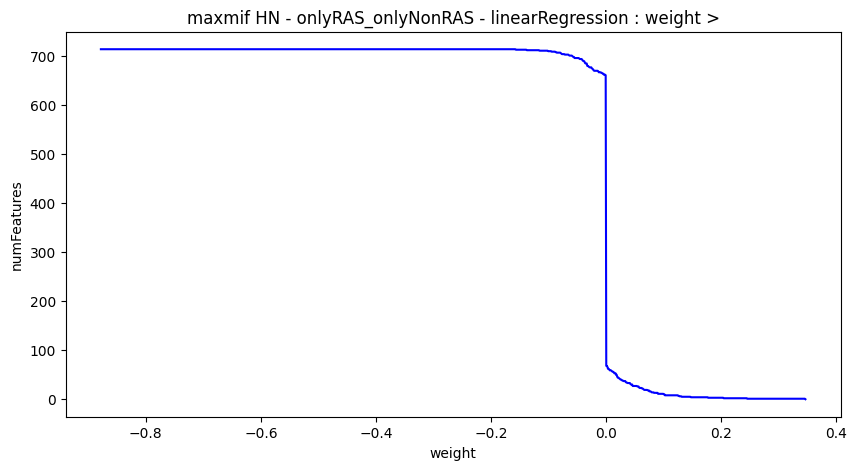

In [27]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

ax.plot(plot_LRl_mutsig_ALL_onlyMutclust['weight'], plot_LRl_mutsig_ALL_onlyMutclust['numFeatures'], color='blue')
ax.set_xlabel('weight')
ax.set_ylabel('numFeatures')
ax.set_title('maxmif HN - onlyRAS_onlyNonRAS - linearRegression : weight >')

In [28]:
RAS_significantFeatures_LRl_mutsig_ALL_onlyMutclust = set(weights_LRl_mutsig_ALL_onlyMutclust[weights_LRl_mutsig_ALL_onlyMutclust['weight'] > 0]['feature'])
weights_LRl_mutsig_ALL_onlyMutclust[weights_LRl_mutsig_ALL_onlyMutclust['feature'].isin(RAS_significantFeatures_LRl_mutsig_ALL_onlyMutclust)]

,feature,gene,weight
415,PCBP1_100_102,PCBP1,0.346050
441,PIK3CA_545_546,PIK3CA,0.244198
34,APC_1281_1554,APC,0.203855
100,CASP8_470_471,CASP8,0.176391
582,TARBP2_210_225,TARBP2,0.146913
...,...,...,...
61,ATP6V1C2_230_230,ATP6V1C2,0.002668
650,USP5_75_86,USP5,0.002617
516,SENP1_409_409,SENP1,0.002596
695,ZNF430_308_318,ZNF430,0.001971


In [29]:
weights_LRl_mutsig_ALL_onlyMutclust[weights_LRl_mutsig_ALL_onlyMutclust['feature'].isin(RAS_significantFeatures_LRl_mutsig_ALL_onlyMutclust)].head(10)

,feature,gene,weight
415,PCBP1_100_102,PCBP1,0.346050
441,PIK3CA_545_546,PIK3CA,0.244198
34,APC_1281_1554,APC,0.203855
100,CASP8_470_471,CASP8,0.176391
582,TARBP2_210_225,TARBP2,0.146913
426,PDIA5_383_384,PDIA5,0.130274
41,APC_874_876,APC,0.126864
198,FBXW7_465_465,FBXW7,0.124771
704,ZNF555_73_75,ZNF555,0.101911
167,DSEL_969_970,DSEL,0.101245


In [30]:
len(train_RAS[train_RAS[list(RAS_significantFeatures_LRl_mutsig_ALL_onlyMutclust)].sum(axis=1) > 0]), \
len(train_nonRAS[train_nonRAS[list(RAS_significantFeatures_LRl_mutsig_ALL_onlyMutclust)].sum(axis=1) > 0]), \
len(test_RAS[test_RAS[list(RAS_significantFeatures_LRl_mutsig_ALL_onlyMutclust)].sum(axis=1) > 0]), \
len(test_nonRAS[test_nonRAS[list(RAS_significantFeatures_LRl_mutsig_ALL_onlyMutclust)].sum(axis=1) > 0])

(280, 252, 112, 115)

In [31]:
len(train_RAS), len(train_nonRAS), len(test_RAS), len(test_nonRAS)

(332, 451, 143, 193)

In [32]:
valid_features = info_mutsig_ALL_onlyMutclust['valid_features_train']

In [33]:
len(train_RAS[valid_features].loc[~(train_RAS[valid_features] == 0).all(axis=1)]), \
len(train_nonRAS[valid_features].loc[~(train_nonRAS[valid_features] == 0).all(axis=1)]), \
len(test_RAS[valid_features].loc[~(test_RAS[valid_features] == 0).all(axis=1)]), \
len(test_nonRAS[valid_features].loc[~(test_nonRAS[valid_features] == 0).all(axis=1)])

(320, 423, 136, 181)

In [34]:
RAS_significantFeatures_LRl_mutsig_ALL_onlyMutclust & RAS_significantFeatures_LRl_driverml_RAS_onlyMutclust

{'APC_1281_1554',
 'APC_874_876',
 'DSEL_969_970',
 'PCBP1_100_102',
 'PDIA5_383_384',
 'PIK3CA_545_546',
 'TICAM1_642_642'}

CASP8:
- **ACTIONABLE** - Patented-recorded target
- tumor suppressor
- pro-apoptotic protein
- inactivated by mutation or deletion in various cancer types

TARBP2:
- associated with Hematologic Cancer and Pleuropulmonary Blastoma

FBXW7:
- **ACTIONABLE** - Literature-reported target
- tumor suppressor involved in protein degradation
- inactivated by mutation in various cancer types, most frequently in endometrial and colorectal cancers

ZNF555: